# Stage 4a: Exploratory Analysis (ratings, length, helpful votes, verified purchase)
Queries the full 18M-review table `MARTS.FCT_REVIEWS` in Snowflake. Only small summary tables come back to your laptop.

**Output:** charts in `reports/figures/` and tables in `reports/tables/` (use them in the report and slides).

**Needs:** Stage 3 finished (`dbt build --target prod`).

## 1. Connect

In [1]:
import getpass
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import snowflake.connector

ACCOUNT   = "SDTPFIN-KG72944"
USER      = "XIEZUOYE33@GMAIL.COM"             # each teammate uses their own Snowflake user
ROLE      = "PROJECT_ROLE"
WAREHOUSE = "COMPUTE_WH"
DB        = "DATA226GROUPPROJECT"

CATEGORIES = ["Books", "Music", "Video_DVD", "Digital_Ebook"]
COLORS = {"Books": "#0072B2", "Music": "#E69F00", "Video_DVD": "#009E73", "Digital_Ebook": "#CC79A7"}

FIG_DIR, TAB_DIR = Path("reports/figures"), Path("reports/tables")
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

conn = snowflake.connector.connect(
    account=ACCOUNT, user=USER,
    password=getpass.getpass("Snowflake password or token: "),
    role=ROLE, warehouse=WAREHOUSE, database=DB,
)
cur = conn.cursor()

def q(sql):
    """Run a query and return a pandas DataFrame with numeric columns converted."""
    cur.execute(sql)
    df = pd.DataFrame(cur.fetchall(), columns=[c[0].lower() for c in cur.description])
    for col in df.columns:
        if df[col].dtype == object:
            try:
                df[col] = pd.to_numeric(df[col])
            except (ValueError, TypeError):
                pass
    return df

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150)
    plt.show()

def save_table(df, name, index=True):
    df.to_csv(TAB_DIR / f"{name}.csv", index=index)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
print(q("SELECT CURRENT_USER(), CURRENT_ROLE()").iloc[0].tolist())

['xiezuoye33', 'PROJECT_ROLE']


In [2]:
FCT = f"{DB}.MARTS.FCT_REVIEWS"
RATING_COLORS = {1: "#d73027", 2: "#fc8d59", 3: "#d9d9d9", 4: "#91bfdb", 5: "#4575b4"}

## 2. Rating distribution per category
Question: how skewed are the ratings, and does it differ by category?

                reviews  avg_rating  pct_1_2_star  pct_3_star  pct_5_star
category                                                                 
Books           3105433        4.18         13.03        8.05       60.05
Music           4748339        4.44          7.43        6.56       69.24
Video_DVD       5063668        4.30         10.69        7.62       65.67
Digital_Ebook   5101681        4.24          9.61        9.45       57.88
All            18019121        4.30          9.93        7.93       63.44


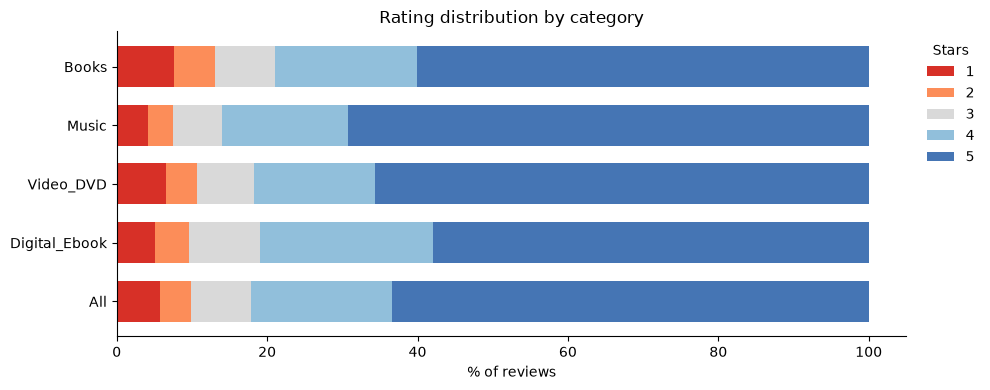

In [3]:
dist = q(f"SELECT category, star_rating, COUNT(*) AS n FROM {FCT} GROUP BY category, star_rating")
dist["star_rating"] = dist["star_rating"].astype(int)
counts = dist.pivot(index="category", columns="star_rating", values="n").reindex(CATEGORIES)
counts.loc["All"] = counts.sum()
share = counts.div(counts.sum(axis=1), axis=0) * 100

summary = pd.DataFrame({
    "reviews": counts.sum(axis=1).astype(int),
    "avg_rating": (counts * counts.columns).sum(axis=1) / counts.sum(axis=1),
    "pct_1_2_star": share[[1, 2]].sum(axis=1),
    "pct_3_star": share[3],
    "pct_5_star": share[5],
}).round(2)
print(summary.to_string())
save_table(summary, "rating_summary")

ax = share.iloc[::-1].plot(kind="barh", stacked=True, figsize=(10, 4),
                           color=[RATING_COLORS[c] for c in share.columns], width=0.7)
ax.set_xlabel("% of reviews"); ax.set_ylabel("")
ax.set_title("Rating distribution by category")
ax.legend(title="Stars", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
save_fig("rating_distribution")

## 3. Review length vs rating
Question: do unhappy customers write longer or shorter reviews?

Median words per review:
category     Books  Music  Video_DVD  Digital_Ebook
star_rating                                        
1            104.0   70.0       71.0           52.0
2            124.0   90.0       97.0           56.0
3            136.0   94.0       88.0           50.0
4            126.0   92.0       71.0           47.0
5            102.0   58.0       37.0           46.0


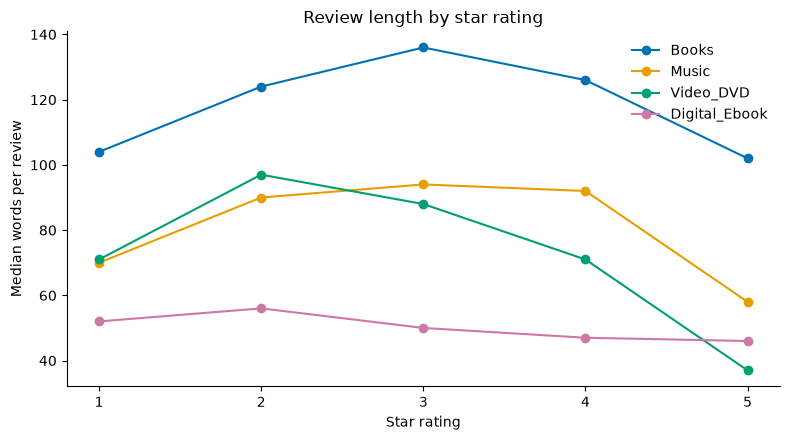

In [4]:
length = q(f"""
    SELECT category, star_rating, COUNT(*) AS n,
           AVG(word_count) AS avg_words, MEDIAN(word_count) AS median_words
    FROM {FCT} GROUP BY category, star_rating ORDER BY category, star_rating
""")
length["star_rating"] = length["star_rating"].astype(int)
med = length.pivot(index="star_rating", columns="category", values="median_words")[CATEGORIES]
print("Median words per review:")
print(med.round(1).to_string())
save_table(length, "length_by_rating", index=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
for cat in CATEGORIES:
    ax.plot(med.index, med[cat], marker="o", color=COLORS[cat], label=cat)
ax.set_xlabel("Star rating"); ax.set_ylabel("Median words per review")
ax.set_xticks([1, 2, 3, 4, 5]); ax.set_title("Review length by star rating")
ax.legend(frameon=False)
save_fig("length_by_rating")

## 4. Helpful votes
Note: older reviews have had more time to collect votes, so also compare within a year before drawing conclusions.

     category  star_rating       n  avg_helpful_votes  share_any_helpful  avg_helpful_ratio
        Books            1  238208             12.450              0.932              0.532
        Books            2  166380             10.074              0.906              0.602
        Books            3  249918              8.562              0.851              0.659
        Books            4  586170              7.744              0.827              0.770
        Books            5 1864757              9.475              0.845              0.799
Digital_Ebook            1  261732              5.991              0.715              0.547
Digital_Ebook            2  228291              3.355              0.612              0.559
Digital_Ebook            3  481927              1.719              0.418              0.592
Digital_Ebook            4 1177120              1.016              0.361              0.739
Digital_Ebook            5 2952611              1.311              0.413        

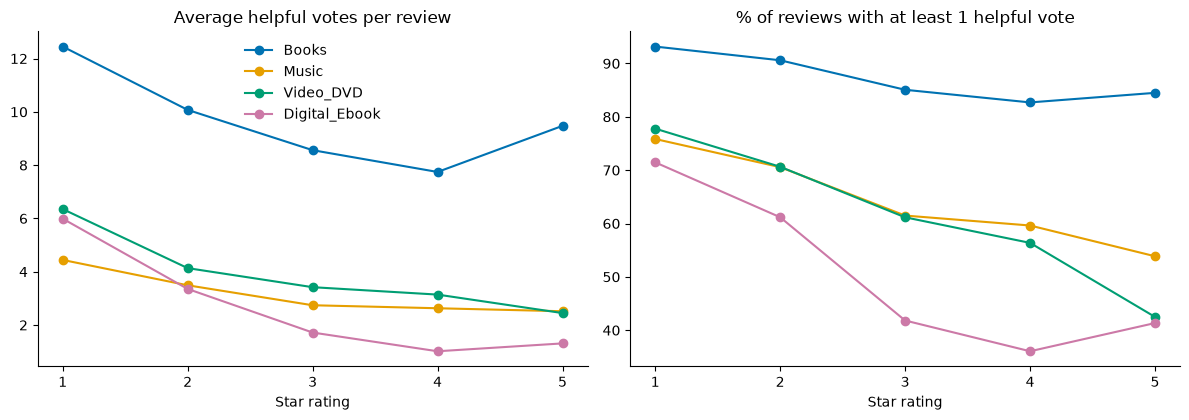

In [5]:
helpful = q(f"""
    SELECT category, star_rating, COUNT(*) AS n,
           AVG(helpful_votes) AS avg_helpful_votes,
           AVG(CASE WHEN helpful_votes > 0 THEN 1.0 ELSE 0.0 END) AS share_any_helpful,
           AVG(CASE WHEN total_votes > 0 THEN helpful_votes * 1.0 / total_votes END) AS avg_helpful_ratio
    FROM {FCT} GROUP BY category, star_rating ORDER BY category, star_rating
""")
helpful["star_rating"] = helpful["star_rating"].astype(int)
print(helpful.round(3).to_string(index=False))
save_table(helpful, "helpful_by_rating", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for cat in CATEGORIES:
    d = helpful[helpful.category == cat]
    axes[0].plot(d.star_rating, d.avg_helpful_votes, marker="o", color=COLORS[cat], label=cat)
    axes[1].plot(d.star_rating, d.share_any_helpful * 100, marker="o", color=COLORS[cat], label=cat)
axes[0].set_title("Average helpful votes per review"); axes[1].set_title("% of reviews with at least 1 helpful vote")
for ax in axes:
    ax.set_xlabel("Star rating"); ax.set_xticks([1, 2, 3, 4, 5])
axes[0].legend(frameon=False)
save_fig("helpful_by_rating")

## 5. Verified purchase

               pct_verified  avg_rating_verified  avg_rating_not_verified
category                                                                 
Books                 7.385                4.180                    4.183
Music                41.267                4.569                    4.343
Video_DVD            65.388                4.483                    3.959
Digital_Ebook        77.276                4.239                    4.246


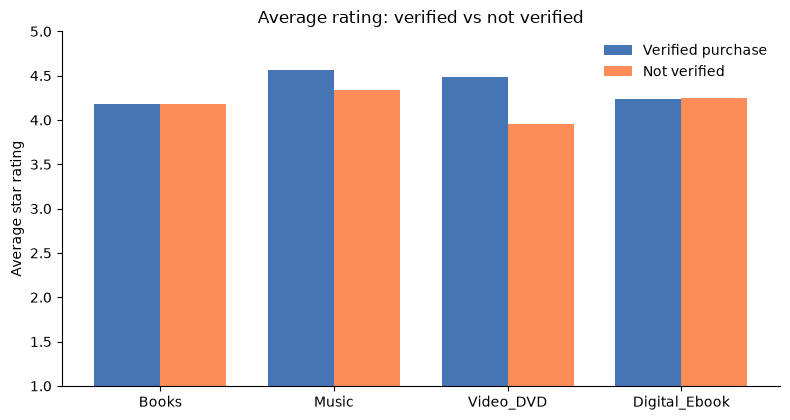

In [6]:
ver = q(f"""
    SELECT category, verified_purchase, star_rating, COUNT(*) AS n
    FROM {FCT} GROUP BY category, verified_purchase, star_rating
""")
ver["w"] = ver["n"] * ver["star_rating"]
agg = ver.groupby(["category", "verified_purchase"], as_index=False).agg(n=("n", "sum"), w=("w", "sum"))
agg["avg_rating"] = agg["w"] / agg["n"]

nn = agg.pivot(index="category", columns="verified_purchase", values="n").reindex(CATEGORIES)
avg = agg.pivot(index="category", columns="verified_purchase", values="avg_rating").reindex(CATEGORIES)
vsum = pd.DataFrame({
    "pct_verified": nn[True] / (nn[True] + nn[False]) * 100,
    "avg_rating_verified": avg[True],
    "avg_rating_not_verified": avg[False],
}).round(3)
print(vsum.to_string())
save_table(vsum, "verified_summary")

x = np.arange(len(CATEGORIES)); w = 0.38
fig, ax = plt.subplots(figsize=(8, 4.3))
ax.bar(x - w/2, avg[True], w, label="Verified purchase", color="#4575b4")
ax.bar(x + w/2, avg[False], w, label="Not verified", color="#fc8d59")
ax.set_xticks(x); ax.set_xticklabels(CATEGORIES)
ax.set_ylim(1, 5); ax.set_ylabel("Average star rating")
ax.set_title("Average rating: verified vs not verified"); ax.legend(frameon=False)
save_fig("verified_avg_rating")

## 6. Trends over time
Years with fewer than 2,000 reviews in a category are left out of the rate charts because they are too noisy.

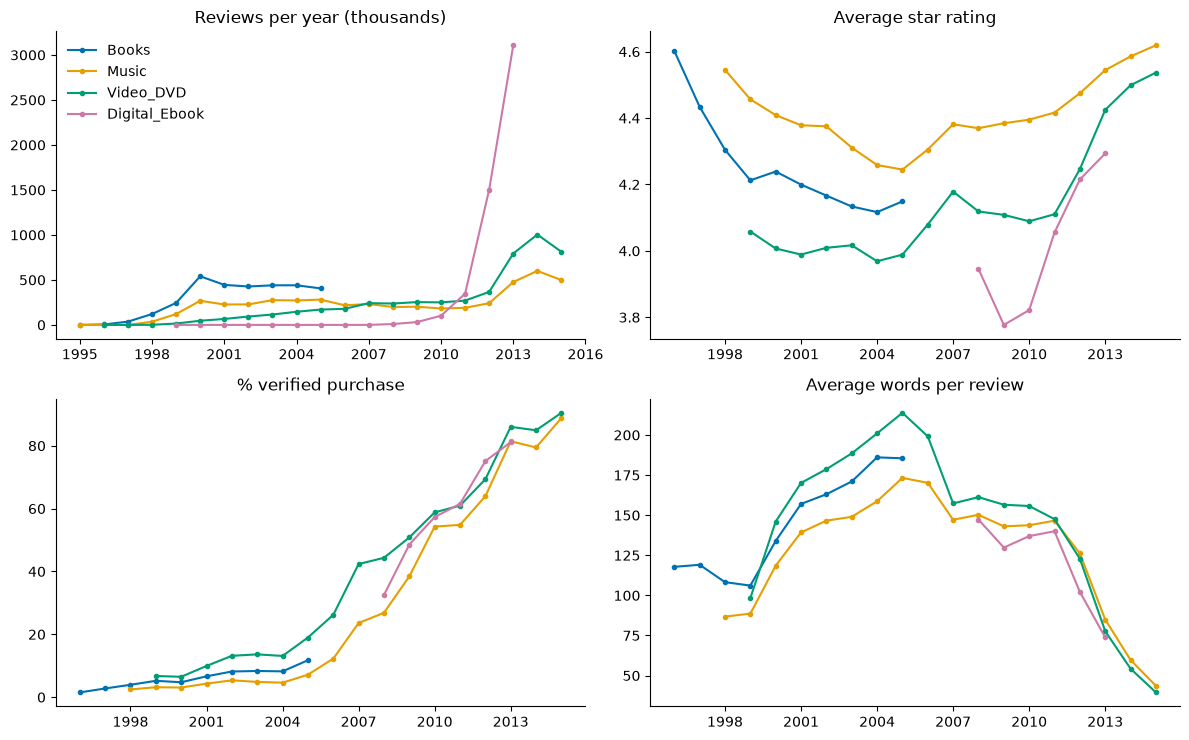

In [7]:
yr = q(f"""
    SELECT category, review_year, COUNT(*) AS n,
           AVG(star_rating) AS avg_rating, AVG(word_count) AS avg_words,
           AVG(CASE WHEN verified_purchase THEN 1.0 ELSE 0.0 END) AS verified_share,
           AVG(helpful_votes) AS avg_helpful
    FROM {FCT} GROUP BY category, review_year ORDER BY category, review_year
""")
yr["review_year"] = yr["review_year"].astype(int)
save_table(yr, "by_category_year", index=False)

from matplotlib.ticker import MaxNLocator

MIN_N = 2000
panels = [("n", "Reviews per year (thousands)", 1e-3), ("avg_rating", "Average star rating", 1),
          ("verified_share", "% verified purchase", 100), ("avg_words", "Average words per review", 1)]
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for ax, (col, title, scale) in zip(axes.ravel(), panels):
    data = yr if col == "n" else yr[yr.n >= MIN_N]
    for cat in CATEGORIES:
        d = data[data.category == cat]
        ax.plot(d.review_year, d[col] * scale, marker="o", ms=3, color=COLORS[cat], label=cat)
    ax.set_title(title)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))   # whole years only
axes[0, 0].legend(frameon=False)
save_fig("trends_over_time")

## 7. Category and year coverage (important for the experiments)
If a category is concentrated in a few years, a cross-category result could partly be a time-period effect. This table shows how each category's reviews are spread across the train and test windows of the temporal experiment.

               pct_before_2000  pct_2000_2012_train  pct_2013_2015_test
category                                                               
Books                     13.1                 86.9                 0.0
Music                      3.3                 63.5                33.2
Video_DVD                  0.3                 48.1                51.6
Digital_Ebook              0.0                 39.1                60.9


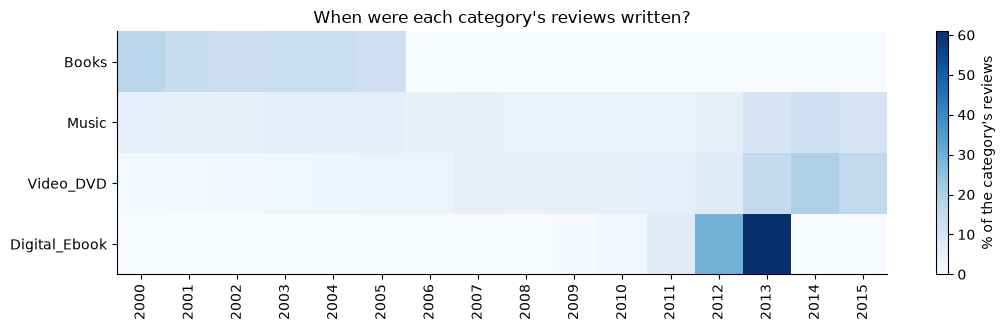

In [8]:
cov = yr.pivot(index="review_year", columns="category", values="n").reindex(columns=CATEGORIES).fillna(0)
cov_share = cov.div(cov.sum(axis=0), axis=1) * 100

windows = pd.DataFrame({
    "pct_before_2000":     cov_share.loc[:1999].sum(),
    "pct_2000_2012_train": cov_share.loc[2000:2012].sum(),
    "pct_2013_2015_test":  cov_share.loc[2013:2015].sum(),
}).round(1)
print(windows.to_string())
save_table(windows, "category_year_windows")

hm = cov_share.loc[2000:2015].T
fig, ax = plt.subplots(figsize=(11, 3.4))
im = ax.imshow(hm.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(hm.shape[1])); ax.set_xticklabels([int(c) for c in hm.columns], rotation=90)
ax.set_yticks(range(hm.shape[0])); ax.set_yticklabels(hm.index)
fig.colorbar(im, ax=ax, label="% of the category's reviews")
ax.set_title("When were each category's reviews written?")
save_fig("category_year_heatmap")

In [9]:
conn.close()
print("Saved figures:", sorted(p.name for p in FIG_DIR.glob("*.png")))
print("Saved tables: ", sorted(p.name for p in TAB_DIR.glob("*.csv")))

Saved figures: ['category_year_heatmap.png', 'helpful_by_rating.png', 'length_by_rating.png', 'rating_distribution.png', 'trends_over_time.png', 'verified_avg_rating.png']
Saved tables:  ['by_category_year.csv', 'category_year_windows.csv', 'helpful_by_rating.csv', 'length_by_rating.csv', 'rating_summary.csv', 'verified_summary.csv']


**Done with 4a.** Send the printed tables to your teammates (or to me) to write up the findings. Next is `04b_eda_words.ipynb`: the words and phrases behind high and low ratings.